# Virtual Painter: tracking a coloured pen when the light changes

**The question:** the virtual painter lets you draw in the air with a coloured pen: the webcam finds the pen's colour, follows its tip and paints a line where it goes. The legacy script found the pen with three hand-tuned colour ranges that a slider tool had set in one room. It looks magical in the room it was tuned in. *But what happens when the light gets dimmer, brighter or warmer, when a big object of the same colour is in view, or when the lighting flickers during a stroke? And can a few small changes make it robust?* Every photo here is **synthetic with a known pen position**, over real background photographs, so success is something we can count.

**How this notebook works.** Each section starts with a plain-English explanation, then the code, then a "how to read this" note.

1. The analogy
2. Setup
3. Audit: a pen in front of real photographs
4. Hypotheses and why we chose each test
5. Four ways to find the pen
6. H1: what does brightness do?
7. H2: what about the colour of the light, overall?
8. H3: what if a big object has the pen's colour?
9. H4: can it follow a stroke while the light flickers?
10. Takeaways
11. Limitations

**Run it:** `uv run jupyter lab CV/virtual-painter/virtual_painter.ipynb`, or *Run All* in any Jupyter. Nothing is downloaded and no camera is needed (the background photographs ship with scikit-image); it takes about 3 minutes on a CPU.

## 1. 💡 The simple analogy

Imagine telling a friend **"find the blue pen"** by describing the exact shade you see in your room right now.

- If the light **dims**, the same pen looks darker and your friend, who is looking for exactly *that* shade, walks right past it.
- If the light gets **brighter or warmer**, the shade drifts again.
- If a **blue book** is in view, a friend who only knows "blue" may point at the book.
- A smarter friend describes the pen by **how its colour is made** (the share of red, green and blue in it, which does not change when the light gets brighter) and also by its **shape and size** ("a small round cap"), so they ignore the book and cope with the dimmer light.

## 2. Setup

*What:* imports and named constants. *Why:* one place for numbers like the seed, the photo size and the success tolerance keeps the notebook reproducible and avoids "magic numbers". There is no camera: the scenes are drawn by code.

In [1]:
import warnings
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from skimage import data as skdata
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.proportion import proportion_confint

warnings.filterwarnings("ignore")
OUT_DIR = Path("outputs")
SEED = 365
W, H = 640, 480  # the legacy camera size
N_SCENES = 100  # scenes per setting
TOLERANCE = 12  # a pen tip counts as found if it is within this many pixels of the truth
N_BOOTSTRAP = 2_000
TEAL, ORANGE, NAVY, GREY, PURPLE = "#2a9d8f", "#e76f51", "#264653", "#b8bcc2", "#7b5ea7"

sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)


def fmt_p(p: float) -> str:
    """Formats a p-value, showing values below floating-point precision honestly.

    Args:
        p: The p-value.

    Returns:
        A short string such as ``3.2e-08`` or ``< 1e-300``.
    """
    return "< 1e-300" if float(p) < 1e-300 else f"{float(p):.1e}"

## 3. Audit: a pen in front of real photographs

*What:* each test photo has a **real background** (five public-domain photographs shipped with scikit-image: an astronaut, a coffee cup, a cat, a rocket and a motorcycle), a coloured **pen cap** (a round disc of 14 to 24 pixels radius, blue or green) at a random place, two **distractor discs** (red and yellow), then a lighting change (brightness, a cool or warm colour cast), sensor noise and a little blur. The true pen **tip** (the top centre of the cap, the point the painter draws at) is known exactly. A pen is **found** if the detected tip is within **12 pixels** of the truth. *Why synthetic?* We can vary one thing at a time and know the answer.

> **Problems in the legacy scripts this replaces:** the three colour ranges (`myColors`) were set once with a slider tool in one room and **hard-coded**; the contour finder returned the **last** blob over 500 pixels, not the biggest; it drew a stray dot at (0, 0) whenever nothing was found; the mask tool needed manual retuning for each new pen and lighting; and everything needed a live webcam, so nothing was ever measured.

In [2]:
BACKGROUNDS = [
    cv2.resize(cv2.cvtColor(img, cv2.COLOR_RGB2BGR), (W, H))
    for img in (
        skdata.astronaut(),
        skdata.coffee(),
        skdata.chelsea(),
        skdata.rocket(),
        skdata.stereo_motorcycle()[0]
        if isinstance(skdata.stereo_motorcycle(), tuple)
        else skdata.stereo_motorcycle(),
    )
]
# marker colours as (hue, saturation, value) in OpenCV units (hue 0 to 179), under neutral light
MARKERS = {"blue": (112, 200, 215), "green": (68, 190, 190)}
# the legacy script's hand-tuned ranges: lower and upper (H, S, V) for its blue and green pens
LEGACY_RANGES = {"blue": ((84, 154, 162), (156, 252, 255)), "green": ((54, 52, 95), (91, 214, 214))}
CASTS = {
    "cool": (0.85, 1.0, 1.18),
    "neutral": (1.0, 1.0, 1.0),
    "warm": (1.18, 1.0, 0.85),
}  # B, G, R


def hsv_to_bgr(h: int, s: int, v: int) -> tuple[int, int, int]:
    """Converts one OpenCV (hue, saturation, value) colour to blue, green, red."""
    pixel = cv2.cvtColor(np.uint8([[[h, s, v]]]), cv2.COLOR_HSV2BGR)[0, 0]
    return int(pixel[0]), int(pixel[1]), int(pixel[2])


def make_scene(
    gen: np.random.Generator,
    colour: str,
    brightness: float = 1.0,
    cast: str = "neutral",
    confuser: bool = False,
) -> dict:
    """A photo of a coloured pen cap held in front of a real, busy background.

    Args:
        gen: Random number generator.
        colour: ``"blue"`` or ``"green"``.
        brightness: Scene brightness multiplier (1 = the lighting the pen was calibrated in).
        cast: Colour of the light: ``"cool"``, ``"neutral"`` or ``"warm"``.
        confuser: If true, a large rectangle of the same colour (a book, say) is also in view.

    Returns:
        A dict with the camera ``image``, the true pen-tip ``tip`` (top centre of the cap),
        the cap ``centre`` and ``radius``, and the ``colour``.
    """
    base = BACKGROUNDS[int(gen.integers(len(BACKGROUNDS)))].copy()
    if gen.random() < 0.5:
        base = base[:, ::-1].copy()
    hue, sat, val = MARKERS[colour]
    bgr = hsv_to_bgr(hue + int(gen.integers(-3, 4)), sat, val)
    radius = int(gen.integers(14, 24))
    cx, cy = int(gen.integers(60, W - 60)), int(gen.integers(60, H - 60))
    if confuser:
        bx, by = int(gen.integers(20, W - 200)), int(gen.integers(20, H - 160))
        far = np.hypot(bx + 90 - cx, by + 60 - cy) > 140
        if far:
            cv2.rectangle(base, (bx, by), (bx + 180, by + 120), bgr, -1)
    for dist_hue in (0, 25):  # red and yellow distractor discs
        dx, dy = int(gen.integers(40, W - 40)), int(gen.integers(40, H - 40))
        if np.hypot(dx - cx, dy - cy) > 80:
            cv2.circle(base, (dx, dy), 18, hsv_to_bgr(dist_hue, 200, 215), -1)
    cv2.circle(base, (cx, cy), radius, bgr, -1)
    image = base.astype(np.float32) * np.array(CASTS[cast], np.float32)[None, None, :]
    image = image * brightness + gen.normal(0, 4, image.shape)
    image = cv2.GaussianBlur(image, (0, 0), 0.8)
    return {
        "image": image.clip(0, 255).astype(np.uint8),
        "tip": np.array([cx, cy - radius]),
        "centre": np.array([cx, cy]),
        "radius": radius,
        "colour": colour,
    }


def top_centre(
    mask: np.ndarray, min_area: int = 500, shape_filter: bool = False, last: bool = False
) -> np.ndarray | None:
    """The pen tip found in a colour mask: the top centre of one blob.

    Args:
        mask: Binary mask of pen-coloured pixels.
        min_area: Smallest blob area (pixels) worth considering.
        shape_filter: If true, only blobs of pen-cap size (300 to 3,000 pixels) that are roughly
            round (circularity above 0.7) count.
        last: If true, use the last qualifying blob in the contour list (the legacy behaviour);
            otherwise use the biggest.

    Returns:
        The tip as (x, y), or None if nothing qualified.
    """
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    chosen, chosen_area = None, 0.0
    for cnt in contours:
        area = cv2.contourArea(cnt)
        if area <= (300 if shape_filter else min_area):
            continue
        if shape_filter:
            perimeter = cv2.arcLength(cnt, True)
            if area > 3_000 or perimeter == 0 or 4 * np.pi * area / perimeter**2 < 0.7:
                continue
        if last or area > chosen_area:
            chosen, chosen_area = cnt, area
    if chosen is None:
        return None
    x, y, w, _ = cv2.boundingRect(chosen)
    return np.array([x + w // 2, y])


gen = np.random.default_rng(SEED)
sample = [make_scene(gen, c, b) for c in ("blue", "green") for b in (0.45, 1.0, 1.5)]
print(
    f"{len(BACKGROUNDS)} real photographs (public-domain scikit-image samples) as backgrounds; "
    f"frame {W} x {H}"
)
print("Pen colours (hue, saturation, value): " + ", ".join(f"{k} {v}" for k, v in MARKERS.items()))
print(f"A pen tip counts as found if it is within {TOLERANCE} pixels of the truth")

5 real photographs (public-domain scikit-image samples) as backgrounds; frame 640 x 480
Pen colours (hue, saturation, value): blue (112, 200, 215), green (68, 190, 190)
A pen tip counts as found if it is within 12 pixels of the truth


**How to read this:**

- **Five real background photographs**, each used at 640 x 480 (the legacy camera size), and two pen colours: a **blue** pen (hue 112 on OpenCV's 0 to 179 scale) and a **green** pen (hue 68), both quite saturated.
- **The legacy ranges were written for that kind of pen:** blue hue 84 to 156 with saturation 154 to 252 and brightness 162 to 255; green hue 54 to 91, saturation 52 to 214, brightness 95 to 214. Our pens sit inside them when the light matches the "calibration lighting" (brightness 1, neutral).

## 4. Hypotheses and why we chose each test

| # | Question | H₀ (nothing interesting) | Hₐ | Test |
|---|---|---|---|---|
| H1 | Does brightness change whether fixed colour ranges find the pen? | Same success at every brightness | It falls away from the calibration lighting | Success rate with Wilson intervals at 6 brightness levels, 100 photos per level |
| H2 | Are the four methods equally robust to light overall? | Same success | Differs | 720 photos over 6 brightness levels x 3 light colours x 2 pens; exact McNemar tests |
| H3 | Does a large object of the pen's colour in view fool the finder? | Same success with and without it | Success falls | 100 photos with a big blue or green rectangle; exact McNemar test |
| H4 | Can each method follow a pen through a stroke while the light flickers? | Same share of frames tracked | Differs | 20 sequences of 120 frames; Wilcoxon test paired by sequence |

*Why these tests?* Each photo (or frame) is a yes-or-no result for each method, so rates get **Wilson intervals** and two methods on the *same* photos are compared with the **exact McNemar test**, which uses only the photos where they disagree. For the 20 sequences, the share of frames tracked is a number per sequence, so the paired **Wilcoxon signed-rank test** is the safe choice.

## 5. Four ways to find the pen

*What:* four methods that all end the same way (take the top centre of a blob), so the only difference is how the pen-coloured pixels are chosen:

1. **Legacy fixed HSV ranges:** the legacy script's hand-tuned ranges and its rule of taking the *last* blob over 500 pixels.
2. **Calibrated HSV ranges:** ranges learned automatically from one clean photo of the pen in the calibration lighting (the 1st to 99th percentile of the cap's pixels, widened a little), then the *biggest* blob. This is what "calibrate the pen once" would give.
3. **Chromaticity:** instead of hue and brightness, use each pixel's **share of red and green in the total light** (red / (red + green + blue), and the same for green). Doubling all three channels leaves these shares unchanged, so a uniform change of brightness does not move them. The pen's shares are learned from the calibration photo.
4. **Chromaticity + pen-cap shape:** the same, but only blobs of *pen-cap size* (300 to 3,000 pixels) that are *round* (circularity above 0.7) count.

In [3]:
def mask_legacy(image: np.ndarray, colour: str) -> np.ndarray:
    """The legacy rule: pixels inside fixed, hand-tuned hue/saturation/value ranges."""
    lower, upper = LEGACY_RANGES[colour]
    return cv2.inRange(cv2.cvtColor(image, cv2.COLOR_BGR2HSV), np.array(lower), np.array(upper))


def calibration_pixels(colour: str, seed: int = 0) -> np.ndarray:
    """Pen-cap pixels from a clean, neutrally lit calibration photo (what a user would show).

    Args:
        colour: Pen colour.
        seed: Seed for the calibration photo.

    Returns:
        An array of BGR pixels, shape (n, 3).
    """
    scene = make_scene(np.random.default_rng(10_000 + seed), colour, 1.0, "neutral")
    yy, xx = np.ogrid[:H, :W]
    inside = (xx - scene["centre"][0]) ** 2 + (yy - scene["centre"][1]) ** 2 < (
        scene["radius"] - 3
    ) ** 2
    return scene["image"][inside]


CALIBRATION = {c: calibration_pixels(c) for c in MARKERS}
HSV_CAL = {}
CHROMA_CAL = {}
for colour, pix in CALIBRATION.items():
    hsv = cv2.cvtColor(pix.reshape(-1, 1, 3), cv2.COLOR_BGR2HSV).reshape(-1, 3).astype(float)
    lo = np.percentile(hsv, 1, axis=0) - np.array([8, 40, 40])
    hi = np.percentile(hsv, 99, axis=0) + np.array([8, 40, 40])
    HSV_CAL[colour] = (np.clip(lo, 0, 255).astype(int), np.clip(hi, 0, 255).astype(int))
    total = pix.astype(np.float32).sum(axis=1) + 1e-6
    red, green = pix[:, 2] / total, pix[:, 1] / total
    centre = np.array([np.median(red), np.median(green)])
    spread = np.percentile(np.hypot(red - centre[0], green - centre[1]), 99)
    CHROMA_CAL[colour] = (centre, spread + 0.04)


def mask_hsv_calibrated(image: np.ndarray, colour: str) -> np.ndarray:
    """HSV ranges learned from the calibration photo (so adapted to one lighting only)."""
    lo, hi = HSV_CAL[colour]
    return cv2.inRange(
        cv2.cvtColor(image, cv2.COLOR_BGR2HSV), lo.astype(np.uint8), hi.astype(np.uint8)
    )


def mask_chromaticity(image: np.ndarray, colour: str) -> np.ndarray:
    """Pixels whose share of red and green in the total light is close to the pen's.

    Dividing each channel by the sum of the three removes a uniform change of brightness:
    a pixel twice as bright has the same shares. A pixel must also be bright enough to measure.
    """
    smooth_image = cv2.GaussianBlur(image.astype(np.float32), (0, 0), 1.5)
    total = smooth_image.sum(axis=2) + 1e-6
    red, green = smooth_image[:, :, 2] / total, smooth_image[:, :, 1] / total
    centre, radius = CHROMA_CAL[colour]
    keep = (np.hypot(red - centre[0], green - centre[1]) < radius) & (total > 60)
    return cv2.morphologyEx(keep.astype(np.uint8) * 255, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))


METHODS = {
    "legacy fixed HSV ranges": lambda im, c: top_centre(mask_legacy(im, c), last=True),
    "calibrated HSV ranges": lambda im, c: top_centre(mask_hsv_calibrated(im, c)),
    "chromaticity (colour shares)": lambda im, c: top_centre(mask_chromaticity(im, c)),
    "chromaticity + pen-cap shape": lambda im, c: top_centre(
        mask_chromaticity(im, c), shape_filter=True
    ),
}


def found(tip: np.ndarray | None, truth: np.ndarray) -> bool:
    """Whether a detected tip is within ``TOLERANCE`` pixels of the true tip."""
    return tip is not None and float(np.linalg.norm(tip - truth)) <= TOLERANCE


def wilson(hits: int, total: int) -> tuple[float, float, float]:
    """Share with a 95% Wilson interval."""
    low, high = proportion_confint(hits, total, method="wilson")
    return hits / total, low, high


gen = np.random.default_rng(SEED + 1)
clean = [make_scene(gen, c, 1.0) for c in ("blue", "green") for _ in range(50)]
print(f"Neutral light, brightness 1 (the calibration lighting), {len(clean)} photos:")
for name, fn in METHODS.items():
    ok = sum(found(fn(s["image"], s["colour"]), s["tip"]) for s in clean)
    print(f"  {name}: {ok / len(clean):.0%}")

Neutral light, brightness 1 (the calibration lighting), 100 photos:
  legacy fixed HSV ranges: 100%
  calibrated HSV ranges: 100%


  chromaticity (colour shares): 78%


  chromaticity + pen-cap shape: 100%


**How to read this:**

- **In the calibration lighting, the legacy and calibrated HSV methods find the pen in 100% of 100 photos.** This is what the legacy demo showed.
- **Plain chromaticity finds it in only 78%:** the colour shares of some background regions (a blue sky, a green plant) match the pen's, and the biggest such region wins. Adding the pen-cap shape and size filter brings it back to **100%**.

## 6. H1: what does brightness do?

*What:* the same 100 photos at six brightness levels: 0.35, 0.5, 0.7, **1.0** (the calibration lighting), 1.3 and 1.6, in neutral light, all four methods, with Wilson intervals. *Why:* lighting changes all the time (clouds, a lamp, the time of day), and it is the first thing a webcam painter meets.

In [4]:
BRIGHTNESS = [0.35, 0.5, 0.7, 1.0, 1.3, 1.6]
rows = []
for level in BRIGHTNESS:
    gen = np.random.default_rng(SEED + int(level * 100))
    scenes = [make_scene(gen, c, level) for c in ("blue", "green") for _ in range(N_SCENES // 2)]
    for name, fn in METHODS.items():
        hits = sum(found(fn(s["image"], s["colour"]), s["tip"]) for s in scenes)
        share, low, high = wilson(hits, len(scenes))
        rows.append(
            {"brightness": level, "method": name, "found": share, "ci_low": low, "ci_high": high}
        )
bright = pd.DataFrame(rows)
tab = bright.pivot(index="brightness", columns="method", values="found")[list(METHODS)]
print(
    f"Share of {N_SCENES} photos in which the pen tip is found, by brightness "
    "(1.0 = calibration lighting):"
)
print((tab * 100).round(0).astype(int).to_string())

Share of 100 photos in which the pen tip is found, by brightness (1.0 = calibration lighting):
method      legacy fixed HSV ranges  calibrated HSV ranges  chromaticity (colour shares)  chromaticity + pen-cap shape
brightness                                                                                                            
0.35                              0                      0                            89                           100
0.50                              3                      0                            91                           100
0.70                             50                      0                            88                           100
1.00                            100                    100                            81                           100
1.30                             59                     60                            80                            92
1.60                             49                     49              

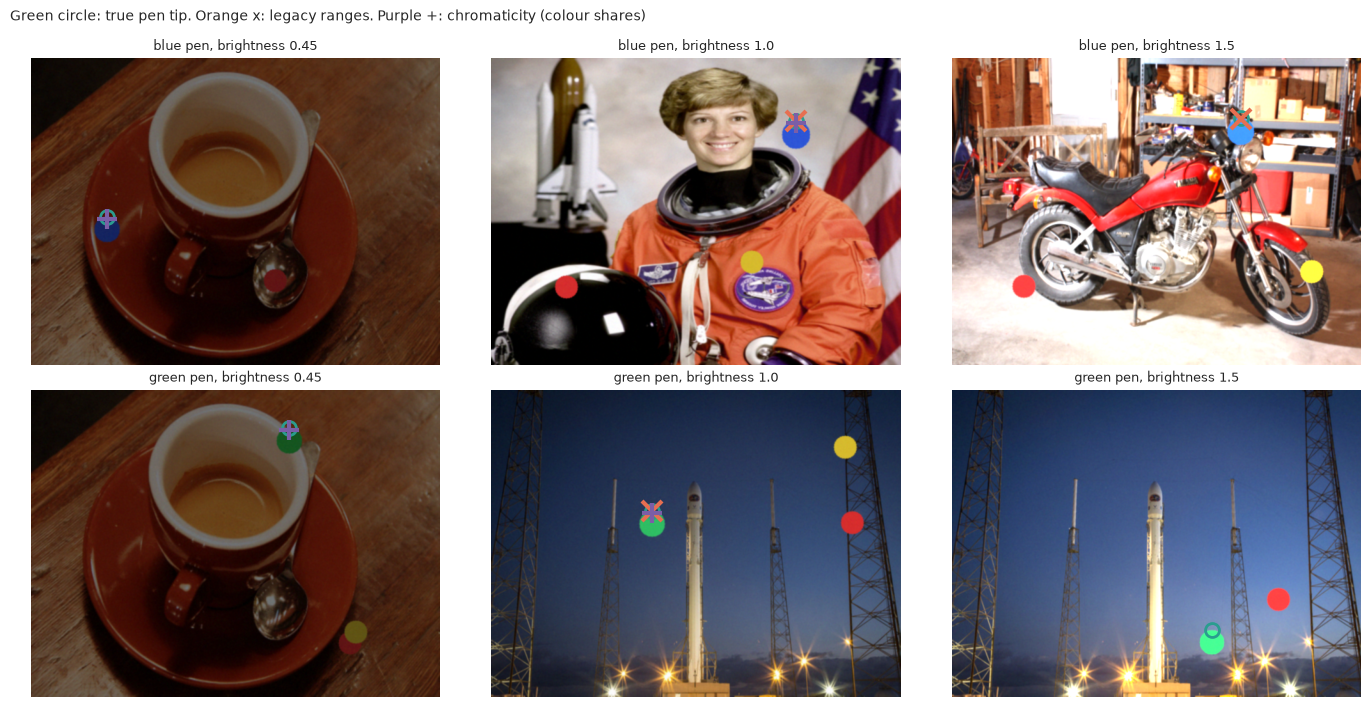

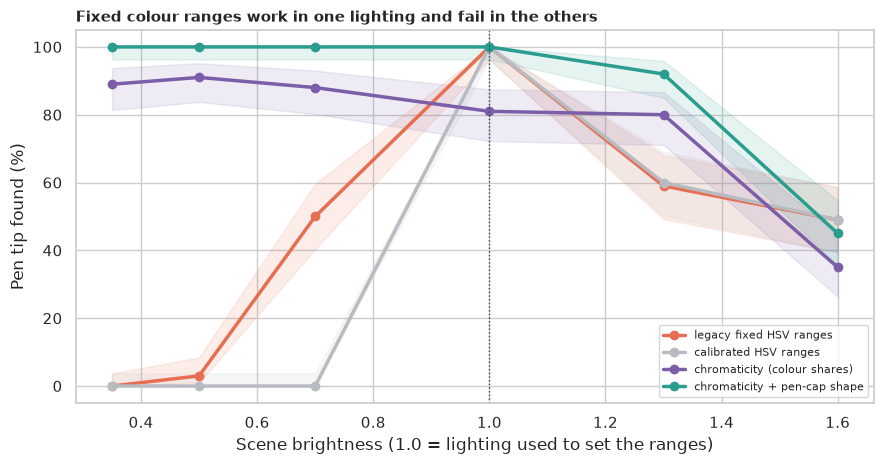

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.2))
gen = np.random.default_rng(SEED + 5)
for row, colour in enumerate(("blue", "green")):
    for col, level in enumerate((0.45, 1.0, 1.5)):
        scene = make_scene(gen, colour, level)
        ax = axes[row, col]
        ax.imshow(cv2.cvtColor(scene["image"], cv2.COLOR_BGR2RGB))
        ax.plot(*scene["tip"], marker="o", ms=10, mfc="none", mec=TEAL, mew=2)
        for name, color, marker in [
            ("legacy fixed HSV ranges", ORANGE, "x"),
            ("chromaticity (colour shares)", PURPLE, "+"),
        ]:
            tip = METHODS[name](scene["image"], colour)
            if tip is not None:
                ax.plot(*tip, marker=marker, ms=14, mec=color, mew=3, ls="")
        ax.set_title(f"{colour} pen, brightness {level}", fontsize=9)
        ax.axis("off")
fig.suptitle(
    "Green circle: true pen tip. Orange x: legacy ranges. Purple +: chromaticity (colour shares)",
    x=0.01,
    ha="left",
    fontsize=10,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "01_examples.png", dpi=110)
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.8))
for name, color in zip(METHODS, [ORANGE, GREY, PURPLE, TEAL], strict=True):
    sub = bright[bright["method"] == name]
    ax.plot(sub["brightness"], sub["found"] * 100, marker="o", lw=2.5, color=color, label=name)
    ax.fill_between(
        sub["brightness"], sub["ci_low"] * 100, sub["ci_high"] * 100, color=color, alpha=0.12
    )
ax.axvline(1.0, color=NAVY, ls=":", lw=1)
ax.set_xlabel("Scene brightness (1.0 = lighting used to set the ranges)")
ax.set_ylabel("Pen tip found (%)")
ax.set_title(
    "Fixed colour ranges work in one lighting and fail in the others",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT_DIR / "02_brightness.png", dpi=150)
plt.show()

**How to read this:**

- **Both HSV methods work in exactly one lighting:** the legacy ranges find the pen in **100%** of photos at brightness 1.0 but **50%** at 0.7, **3%** at 0.5 and **0%** at 0.35 (and **59%** at 1.3, **49%** at 1.6). The calibrated HSV ranges are even narrower: **0%** at 0.7 and below, **60%** at 1.3, **49%** at 1.6.
- **Chromaticity does not care about dimming:** plain chromaticity finds the pen in **89%** at 0.35, **91%** at 0.5, **88%** at 0.7 and **80% to 81%** at 1.0 to 1.3. With the pen-cap shape filter it is **100%** from 0.35 up to 1.0 and **92%** at 1.3.
- **Everything fails when the image is over-exposed:** at brightness 1.6 the pen's bright channels hit the 255 ceiling and the colour shares change (chromaticity **35%**, with shape **45%**, HSV **49%**). Clipped pixels have lost their colour: no method can bring that back.
- **We reject H₀.** The figure shows examples (green circle: the true tip; orange x: legacy; purple +: chromaticity) and the success curves with their Wilson bands.

## 7. H2: what about the colour of the light, overall?

*What:* first, the success rate at brightness 1.0 under a **cool**, **neutral** and **warm** colour cast (the light tinting every colour). Then, pooling **all 720 photos** (6 brightness levels x 3 light colours x 2 pens, 20 photos each), the overall success rate of each method with Wilson intervals, and **exact McNemar tests** of the best method against the legacy and against the calibrated HSV method. *Why:* real lighting changes both brightness and colour, usually together.

In [6]:
rows = []
cast_ok = {}
for cast in CASTS:
    gen = np.random.default_rng(SEED + 77)
    scenes = [
        make_scene(gen, c, 1.0, cast) for c in ("blue", "green") for _ in range(N_SCENES // 2)
    ]
    for name, fn in METHODS.items():
        flags = np.array([found(fn(s["image"], s["colour"]), s["tip"]) for s in scenes])
        cast_ok[(cast, name)] = flags
        share, low, high = wilson(int(flags.sum()), len(flags))
        rows.append({"light": cast, "method": name, "found": share, "ci_low": low, "ci_high": high})
casts = pd.DataFrame(rows)
print(
    (casts.pivot(index="light", columns="method", values="found")[list(METHODS)] * 100)
    .round(0)
    .astype(int)
    .to_string()
)
# paired comparison pooled over every brightness and cast setting
pooled = {name: [] for name in METHODS}
for level in BRIGHTNESS:
    for cast in CASTS:
        gen = np.random.default_rng(SEED + 500 + int(level * 100) + len(cast))
        scenes = [make_scene(gen, c, level, cast) for c in ("blue", "green") for _ in range(20)]
        for name, fn in METHODS.items():
            pooled[name] += [found(fn(s["image"], s["colour"]), s["tip"]) for s in scenes]
pooled = {k: np.array(v) for k, v in pooled.items()}
n_all = len(next(iter(pooled.values())))
print(f"\nAll {n_all:,} photos (6 brightness levels x 3 light colours x 2 pens):")
for name in METHODS:
    share, low, high = wilson(int(pooled[name].sum()), n_all)
    print(f"  {name}: {share:.1%} (95% CI {low:.1%} to {high:.1%})")
a, b = pooled["chromaticity + pen-cap shape"], pooled["legacy fixed HSV ranges"]
mc = mcnemar(
    [[int((a & b).sum()), int((a & ~b).sum())], [int((~a & b).sum()), int((~a & ~b).sum())]],
    exact=True,
)
print(
    f"Chromaticity + shape finds the tip where legacy fails in {int((a & ~b).sum())} photos; "
    f"the reverse in {int((~a & b).sum())}; exact McNemar p = {fmt_p(mc.pvalue)}"
)
c = pooled["calibrated HSV ranges"]
mc = mcnemar(
    [[int((a & c).sum()), int((a & ~c).sum())], [int((~a & c).sum()), int((~a & ~c).sum())]],
    exact=True,
)
print(
    f"Chromaticity + shape vs calibrated HSV: {int((a & ~c).sum())} vs {int((~a & c).sum())}; "
    f"exact McNemar p = {fmt_p(mc.pvalue)}"
)

method   legacy fixed HSV ranges  calibrated HSV ranges  chromaticity (colour shares)  chromaticity + pen-cap shape
light                                                                                                              
cool                          95                     92                            68                            83
neutral                      100                    100                            82                           100
warm                         100                    100                            67                            73



All 720 photos (6 brightness levels x 3 light colours x 2 pens):
  legacy fixed HSV ranges: 44.3% (95% CI 40.7% to 48.0%)
  calibrated HSV ranges: 34.4% (95% CI 31.1% to 38.0%)
  chromaticity (colour shares): 61.3% (95% CI 57.6% to 64.7%)
  chromaticity + pen-cap shape: 73.5% (95% CI 70.1% to 76.6%)
Chromaticity + shape finds the tip where legacy fails in 294 photos; the reverse in 84; exact McNemar p = 2.0e-28
Chromaticity + shape vs calibrated HSV: 355 vs 74; exact McNemar p = 4.3e-45


**How to read this:**

- **Colour casts matter less than brightness for the HSV methods** (their hue ranges are wide): the legacy ranges find the pen in **95%** (cool), **100%** (neutral) and **100%** (warm) of photos at brightness 1.0, the calibrated ranges **92%, 100%, 100%**. Chromaticity is **more sensitive to casts**: plain chromaticity **68%, 82%, 67%**, with the shape filter **83%, 100%, 73%**, because a cast shifts the colour shares.
- **Over all 720 photos:** legacy **44.3%** (95% CI 40.7% to 48.0%), calibrated HSV **34.4%** (31.1% to 38.0%), chromaticity **61.3%** (57.6% to 64.7%), chromaticity + shape **73.5%** (70.1% to 76.6%).
- **Calibrating the pen once makes things worse, not better:** the calibrated ranges are tighter than the legacy hand-tuned ones, so they break sooner when the light changes. The legacy ranges worked better because they were broad, not because they were well chosen.
- **The best method beats the legacy one on the same photos:** chromaticity + shape finds the pen where the legacy fails in **294** photos and fails where the legacy succeeds in **84** (McNemar p = 2e-28), and beats the calibrated HSV 355 to 74 (p = 4e-45). **We reject H₀.**

## 8. H3: what if a big object has the pen's colour?

*What:* 100 photos in the calibration lighting where, besides the pen, a **large rectangle of the pen's colour** (180 x 120 pixels, a book or a folder) is somewhere else in the picture. The legacy rule takes the *last* blob over 500 pixels, and a "largest blob" rule would take the rectangle. The shape filter keeps only round blobs of pen-cap size. We compare it with the legacy method using an exact McNemar test. *Why:* a desk has many coloured objects, and a colour is not an identity.

In [7]:
gen = np.random.default_rng(SEED + 99)
conf_scenes = [
    make_scene(gen, c, 1.0, "neutral", confuser=True)
    for c in ("blue", "green")
    for _ in range(N_SCENES // 2)
]
rows = []
for name, fn in METHODS.items():
    flags = np.array([found(fn(s["image"], s["colour"]), s["tip"]) for s in conf_scenes])
    share, low, high = wilson(int(flags.sum()), len(flags))
    rows.append({"method": name, "found": share, "ci_low": low, "ci_high": high})
conf = pd.DataFrame(rows).set_index("method")
print(
    f"{len(conf_scenes)} photos with a large rectangle of the pen's colour in view, in the "
    "calibration lighting:"
)
print((conf * 100).round(0).astype(int).to_string())
legacy_flags = np.array(
    [
        found(METHODS["legacy fixed HSV ranges"](s["image"], s["colour"]), s["tip"])
        for s in conf_scenes
    ]
)
shape_flags = np.array(
    [
        found(METHODS["chromaticity + pen-cap shape"](s["image"], s["colour"]), s["tip"])
        for s in conf_scenes
    ]
)
mc = mcnemar(
    [
        [int((shape_flags & legacy_flags).sum()), int((shape_flags & ~legacy_flags).sum())],
        [int((~shape_flags & legacy_flags).sum()), int((~shape_flags & ~legacy_flags).sum())],
    ],
    exact=True,
)
print(
    f"Shape filter vs legacy: {int((shape_flags & ~legacy_flags).sum())} photos only the shape "
    f"filter gets, {int((~shape_flags & legacy_flags).sum())} only legacy; exact McNemar "
    f"p = {fmt_p(mc.pvalue)}"
)

100 photos with a large rectangle of the pen's colour in view, in the calibration lighting:
                              found  ci_low  ci_high
method                                              
legacy fixed HSV ranges          47      38       57
calibrated HSV ranges            24      17       33
chromaticity (colour shares)     23      16       32
chromaticity + pen-cap shape    100      96      100


Shape filter vs legacy: 53 photos only the shape filter gets, 0 only legacy; exact McNemar p = 2.2e-16


**How to read this:**

- **A big blob of the same colour breaks colour-only methods:** the legacy method finds the pen in **47%** of the photos (95% CI 38% to 57%), the calibrated HSV method **24%**, plain chromaticity **23%**. They are picking the rectangle about half to three quarters of the time.
- **The shape filter is immune:** chromaticity + pen-cap shape finds the pen in **100%** of the photos (96% to 100%), because the rectangle is the wrong size and not round. It finds the pen in **53** photos where the legacy fails and loses **0** (McNemar p = 2e-16). **We reject H₀.**
- **The lesson:** "what colour" is not enough; the pen has a **size and a shape** as well, and using them costs a few lines.

## 9. H4: can it follow a stroke while the light flickers?

*What:* a painter is used over time. We simulate **20 sequences of 120 frames** in which the pen traces a looping figure-of-eight while the brightness flickers between **0.7 and 1.3** (a flickering lamp, a passing cloud). For every frame each method is asked for the pen tip, and we record the share of frames in which it is found within 12 pixels. We compare each method with the legacy one, sequence by sequence, with the Wilcoxon test. *Why:* a pen that vanishes for a third of the frames draws a dotted line.

In [8]:
def render_frame(colour: str, centre: np.ndarray, brightness: float, seed: int) -> tuple:
    """One video frame with the pen cap at a given place and brightness.

    Args:
        colour: Pen colour.
        centre: Where the cap is, as (x, y).
        brightness: Scene brightness multiplier.
        seed: Chooses the background photograph and the noise.

    Returns:
        The frame and the true pen tip.
    """
    gen = np.random.default_rng(seed)
    base = BACKGROUNDS[seed % len(BACKGROUNDS)].copy()
    radius = 18
    cx, cy = int(round(centre[0])), int(round(centre[1]))
    hue, sat, val = MARKERS[colour]
    cv2.circle(base, (cx, cy), radius, hsv_to_bgr(hue, sat, val), -1)
    image = base.astype(np.float32) * brightness + gen.normal(0, 4, base.shape)
    frame = cv2.GaussianBlur(image, (0, 0), 0.8).clip(0, 255).astype(np.uint8)
    return frame, np.array([cx, cy - radius])


N_SEQ, N_FRAMES = 20, 120
rows = []
for s in range(N_SEQ):
    gen = np.random.default_rng(SEED + 1000 + s)
    colour = ("blue", "green")[s % 2]
    phase, flicker_phase = gen.uniform(0, 2 * np.pi, 2)
    bg_index = int(gen.integers(len(BACKGROUNDS)))
    hits = {name: 0 for name in METHODS}
    for t in range(N_FRAMES):
        angle = phase + 2 * np.pi * t / N_FRAMES
        centre = np.array([W / 2 + 190 * np.cos(angle), H / 2 + 110 * np.sin(2 * angle)])
        brightness = 1.0 + 0.3 * np.sin(2 * np.pi * t / 40 + flicker_phase)  # 0.7 to 1.3
        image, tip = render_frame(colour, centre, brightness, bg_index)
        for name, fn in METHODS.items():
            hits[name] += found(fn(image, colour), tip)
    for name, count in hits.items():
        rows.append({"sequence": s, "method": name, "frames tracked": count / N_FRAMES})
tracking = pd.DataFrame(rows)
by_method = tracking.groupby("method")["frames tracked"].agg(["mean", "min", "max"])
print(
    f"{N_SEQ} sequences of {N_FRAMES} frames; the pen draws a loop while the brightness "
    "flickers between 0.7 and 1.3:"
)
print((by_method.loc[list(METHODS)] * 100).round(0).astype(int).to_string())
legacy_track = tracking[tracking["method"] == "legacy fixed HSV ranges"].set_index("sequence")
for name in list(METHODS)[1:]:
    other = tracking[tracking["method"] == name].set_index("sequence")
    diff = other["frames tracked"] - legacy_track["frames tracked"]
    w = stats.wilcoxon(diff) if (diff != 0).any() else None
    print(
        f"  {name} minus legacy: {diff.mean() * 100:+.0f} points of frames tracked "
        f"(better in {(diff > 0).sum()} of {N_SEQ} sequences); "
        f"Wilcoxon p = {fmt_p(w.pvalue) if w else 'n/a'}"
    )

20 sequences of 120 frames; the pen draws a loop while the brightness flickers between 0.7 and 1.3:
                              mean  min  max
method                                      
legacy fixed HSV ranges         77   65   96
calibrated HSV ranges           67   55   77
chromaticity (colour shares)    91   41  100
chromaticity + pen-cap shape   100  100  100
  calibrated HSV ranges minus legacy: -10 points of frames tracked (better in 0 of 20 sequences); Wilcoxon p = 8.7e-05
  chromaticity (colour shares) minus legacy: +14 points of frames tracked (better in 17 of 20 sequences); Wilcoxon p = 7.3e-02
  chromaticity + pen-cap shape minus legacy: +23 points of frames tracked (better in 20 of 20 sequences); Wilcoxon p = 8.1e-05


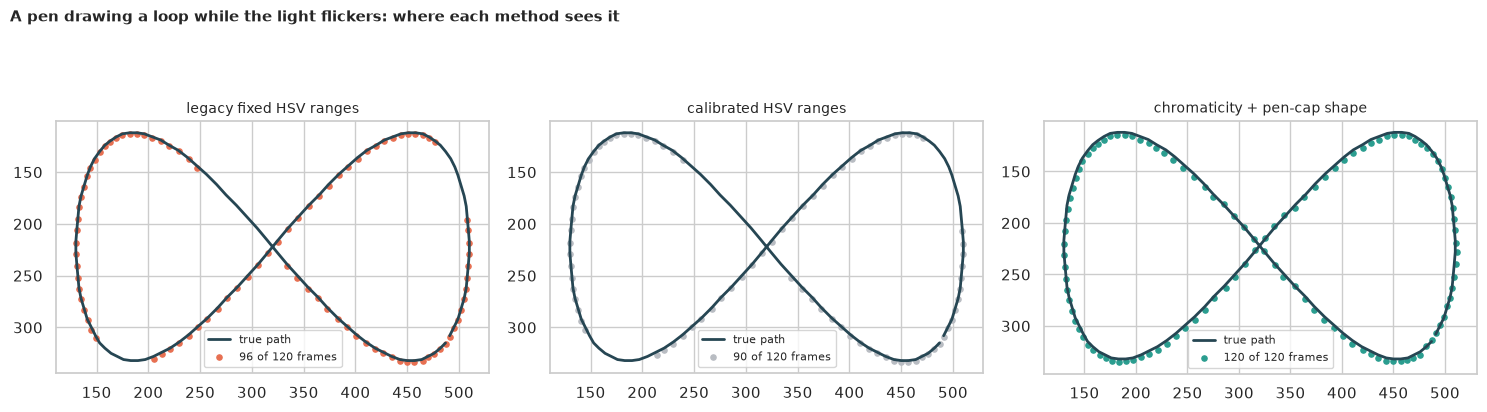

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
colour, phase, flicker_phase, bg_index = "blue", 0.5, 1.0, 0
truth, raw_paths = [], {name: [] for name in METHODS}
for t in range(N_FRAMES):
    angle = phase + 2 * np.pi * t / N_FRAMES
    centre = np.array([W / 2 + 190 * np.cos(angle), H / 2 + 110 * np.sin(2 * angle)])
    brightness = 1.0 + 0.3 * np.sin(2 * np.pi * t / 40 + flicker_phase)
    image, tip = render_frame(colour, centre, brightness, bg_index)
    truth.append(tip)
    for name, fn in METHODS.items():
        raw_paths[name].append(fn(image, colour))
truth = np.array(truth)
for ax, name, color in zip(
    axes,
    ["legacy fixed HSV ranges", "calibrated HSV ranges", "chromaticity + pen-cap shape"],
    [ORANGE, GREY, TEAL],
    strict=True,
):
    ax.plot(truth[:, 0], truth[:, 1], color=NAVY, lw=2, label="true path")
    pts = np.array([p for p in raw_paths[name] if p is not None], float)
    if len(pts):
        ax.scatter(
            pts[:, 0], pts[:, 1], s=14, color=color, label=f"{len(pts)} of {N_FRAMES} frames"
        )
    ax.invert_yaxis()
    ax.set_title(name, fontsize=10)
    ax.legend(fontsize=8)
    ax.set_aspect("equal")
fig.suptitle(
    "A pen drawing a loop while the light flickers: where each method sees it",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "03_paths.png", dpi=150)
plt.show()

**How to read this:**

- **The legacy method tracks the pen in 77% of frames on average** (65% to 96% across sequences), so a stroke is missing about a quarter of its points. The **calibrated HSV** method is worse: **67%** (55% to 77%), worse than the legacy in **all 20 sequences** (Wilcoxon p = 9e-5).
- **Chromaticity improves it to 91% on average** but with a wide spread (**41% to 100%**), better than legacy in 17 of 20 sequences (p = 0.07, not quite significant), because plain chromaticity is distracted by background regions in some of the five photographs.
- **Chromaticity + pen-cap shape tracks the pen in 100% of frames in every sequence** (min 100%, max 100%): **+23 points** against legacy, better in **20 of 20** sequences (Wilcoxon p = 8e-5). **We reject H₀.**
- The figure shows one sequence: the legacy points trace a dotted loop with gaps, the shape-filtered points follow the whole path.

## 10. 🎯 Takeaways

1. **Fixed colour ranges work in one lighting:** the legacy ranges find the pen in 100% of photos at the calibration brightness, 50% at 0.7 of it and 3% at half.
2. **Calibrating once is not the fix:** ranges learned from one clean photo are *tighter* and do worse (34.4% overall against 44.3% for the hand-tuned ones).
3. **Colour shares remove the dimming problem:** chromaticity finds the pen in 88% to 91% of photos even at half the brightness, and with a pen-size and roundness filter, 100%.
4. **A colour is not an identity:** a big object of the pen's colour fools the legacy method in 53% of photos; the shape filter ignores it (100%).
5. **Tracking over time is where it matters:** under a flickering light the legacy method tracks 77% of frames, the best method 100% in every sequence (McNemar and Wilcoxon p below 1e-4).
6. **Some limits are physical:** at brightness 1.6 the colours are clipped and every method falls to 35% to 49%; casts also move colour shares (chromaticity drops to 67% to 83%).

## 11. ⚠️ Limitations

- **Synthetic pens on real photos.** The pen is a clean disc; a real pen cap has highlights, shadows and a hand holding it, and a real webcam adjusts its exposure automatically.
- **Two pen colours and five backgrounds.** Red, orange or skin-coloured pens would be much harder (skin looks like red and orange).
- **Brightness is a simple multiplier.** Real lighting also changes the direction of shadows and adds glare.
- **The methods share one idea** (a colour mask plus the top of a blob); modern trackers use learned detectors and temporal filters, which we did not compare.
- **The "calibrated HSV" method is one particular recipe** (1st to 99th percentile plus a margin); a wider margin would behave more like the legacy one.
- **Colour casts shift chromaticity;** we did not add a white-balance step, which would help.
- **The legacy webcam scripts were not run;** their colour ranges and contour rule were re-implemented in a few lines.